# Cora and CiteSeer citation networks
### CSCE 566 · Problem 4 · Exploratory data analysis

Each node is a paper with a topic label and binary word features. Citation records connect papers. This notebook explores the local LINQS files before training the DeepWalk and GCN benchmarks.

Run from the folder containing `dataset/` with Python 3 and `pandas`, `numpy`, `matplotlib`, and `networkx` installed.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

DATA = Path("dataset")
COLORS = {"Cora": "#196b89", "CiteSeer": "#aa4d26"}
SEED = 42

plt.rcParams.update({
    "figure.dpi": 115,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

## 1. Load the data and audit the citation records

The first and last columns of each `.content` file give the paper ID and topic. The intervening columns are binary word indicators. Paper IDs are read as strings so they match the citation endpoints.

For graph statistics, retain every labeled paper, keep citations whose endpoints both have labels, drop self-loops, and collapse repeated or reciprocal citations to one undirected edge. The table tracks each of these changes separately.

In [2]:
datasets = {}
audit = {}

for name in COLORS:
    stem = name.lower()
    folder = DATA / stem
    papers = pd.read_csv(
        folder / f"{stem}.content", sep="\t", header=None, dtype={0: str}
    )
    citations = pd.read_csv(
        folder / f"{stem}.cites", sep="\t", header=None,
        names=["cited", "citing"], dtype=str,
    )

    labels = papers.iloc[:, -1].set_axis(papers.iloc[:, 0]).rename("topic")
    assert labels.index.is_unique and labels.notna().all()
    features = papers.iloc[:, 1:-1].to_numpy()
    assert ((features == 0) | (features == 1)).all()

    known = citations.isin(labels.index).all(axis=1)
    loops = known & citations["cited"].eq(citations["citing"])
    usable = citations.loc[known & ~loops]
    graph = nx.Graph()
    graph.add_nodes_from(labels.index)
    graph.add_edges_from(usable.itertuples(index=False, name=None))
    assert graph.number_of_nodes() == len(labels)

    datasets[name] = {
        "labels": labels,
        "active_words": features.sum(axis=1),
        "graph": graph,
    }
    audit[name] = {
        "Labeled papers": len(labels),
        "Topics": labels.nunique(),
        "Word features": features.shape[1],
        "Active feature entries (%)": 100 * features.mean(),
        "Raw citation records": len(citations),
        "Records with unknown endpoints": int((~known).sum()),
        "Self-loop records with known endpoints": int(loops.sum()),
        "Repeated or reciprocal records collapsed": len(usable) - graph.number_of_edges(),
        "Unique undirected edges": graph.number_of_edges(),
    }

audit_table = pd.DataFrame(audit)
display(audit_table.style.format("{:,.0f}", subset=(audit_table.index != "Active feature entries (%)", slice(None)))
        .format("{:.2f}", subset=(["Active feature entries (%)"], slice(None))))

,Cora,CiteSeer
Labeled papers,"2,708","3,312"
Topics,7,6
Word features,"1,433","3,703"
Active feature entries (%),1.27,0.86
Raw citation records,"5,429","4,732"
Records with unknown endpoints,0,17
Self-loop records with known endpoints,0,124
Repeated or reciprocal records collapsed,151,55
Unique undirected edges,"5,278","4,536"


## 2. Topic balance and word features

Topic shares show how much accuracy a majority-class predictor would achieve on the full dataset. The word-feature plot counts how many binary indicators are active per paper.

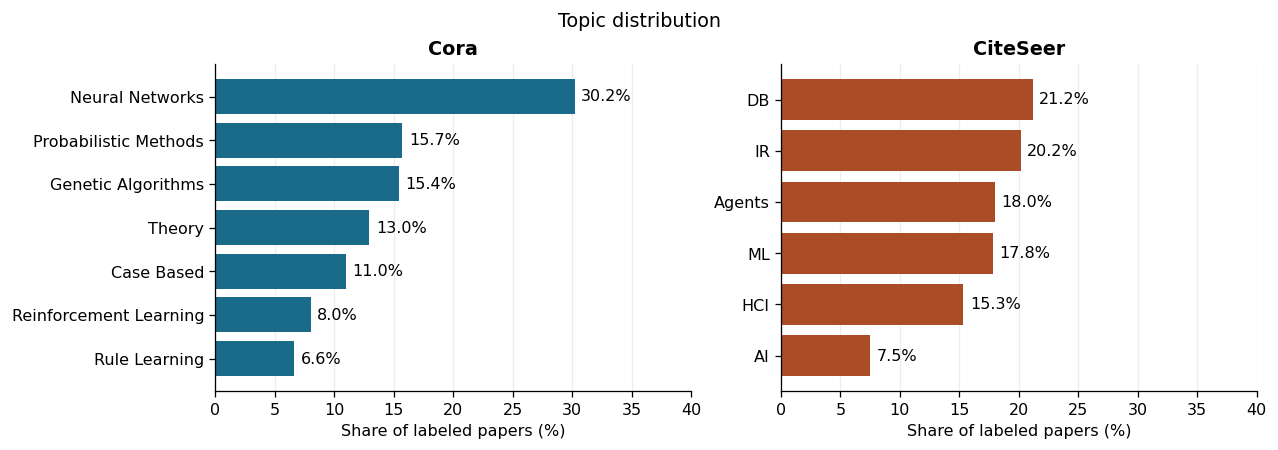

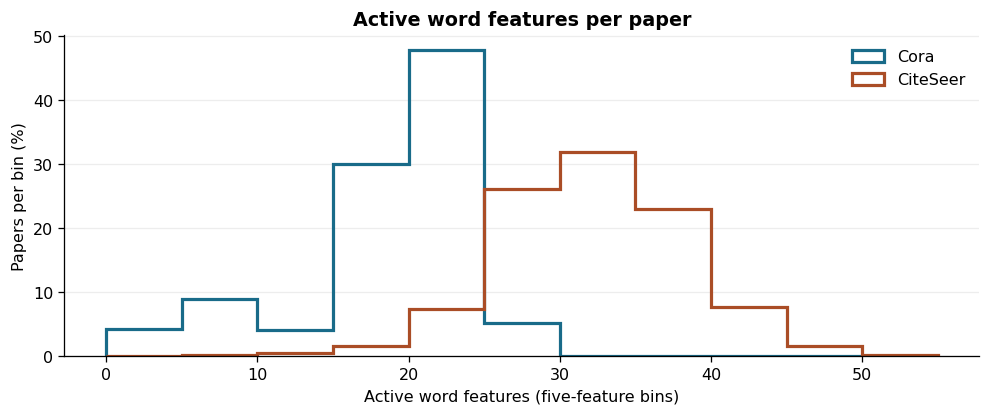

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
for ax, (name, data) in zip(axes, datasets.items()):
    shares = data["labels"].value_counts(normalize=True).sort_values() * 100
    bars = ax.barh(shares.index.str.replace("_", " "), shares, color=COLORS[name])
    ax.bar_label(bars, fmt="%.1f%%", padding=4)
    ax.set(title=name, xlabel="Share of labeled papers (%)", xlim=(0, 40))
    ax.grid(axis="x", alpha=0.22)
fig.suptitle("Topic distribution")
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 3.5), layout="constrained")
bins = np.arange(0, max(data["active_words"].max() for data in datasets.values()) + 6, 5)
for name, data in datasets.items():
    counts = data["active_words"]
    ax.hist(counts, bins=bins, weights=np.full(len(counts), 100 / len(counts)),
            histtype="step", linewidth=2, color=COLORS[name], label=name)
ax.set(title="Active word features per paper",
       xlabel="Active word features (five-feature bins)", ylabel="Papers per bin (%)")
ax.grid(axis="y", alpha=0.22)
ax.legend(frameon=False)
plt.show()

## 3. Connectivity and topic mixing

Degree counts the number of unique neighbors. The degree curve shows the share of papers with at least each degree, including isolates at degree zero.

For topic mixing, compare the observed fraction of same-topic edges with the expected fraction after randomly permuting the existing labels across nodes. This reference preserves topic counts and graph structure.

,Cora,CiteSeer
Connected components,78.00,438.00
Isolated papers,0.00,48.00
Largest component (%),91.77,63.71
Median degree,3.00,2.00
Mean degree,3.90,2.74
Maximum degree,168.00,99.00
Same-topic edges (%),81.00,73.77
Expected same-topic edges after label shuffle (%),17.93,17.85


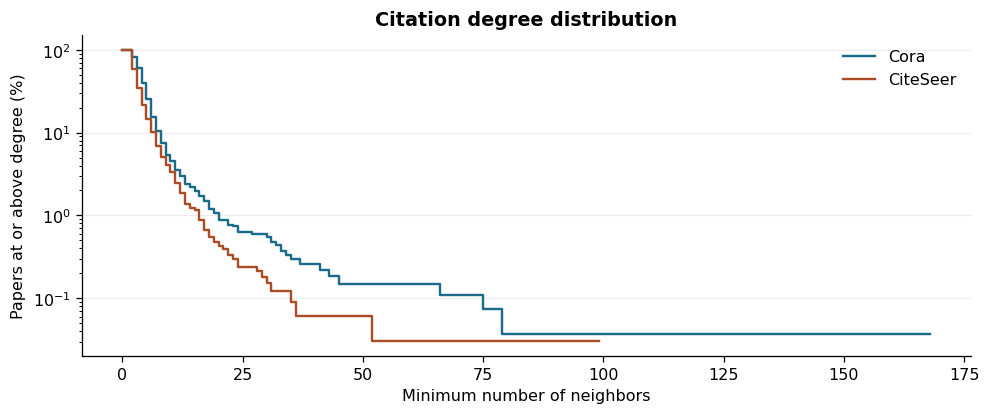

In [4]:
graph_summary = {}
fig, ax = plt.subplots(figsize=(8.5, 3.5), layout="constrained")

for name, data in datasets.items():
    graph, labels = data["graph"], data["labels"]
    degrees = np.array([degree for _, degree in graph.degree()])
    components = sorted(map(len, nx.connected_components(graph)), reverse=True)
    thresholds = np.arange(degrees.max() + 1)
    survival = (degrees[:, None] >= thresholds).mean(axis=0) * 100
    ax.step(thresholds, survival, where="post", color=COLORS[name], label=name)

    topic_counts = labels.value_counts()
    same_topic = sum(labels.at[u] == labels.at[v] for u, v in graph.edges())
    n = len(labels)
    graph_summary[name] = {
        "Connected components": len(components),
        "Isolated papers": int((degrees == 0).sum()),
        "Largest component (%)": 100 * components[0] / n,
        "Median degree": float(np.median(degrees)),
        "Mean degree": degrees.mean(),
        "Maximum degree": int(degrees.max()),
        "Same-topic edges (%)": 100 * same_topic / graph.number_of_edges(),
        "Expected same-topic edges after label shuffle (%)":
            100 * (topic_counts * (topic_counts - 1)).sum() / (n * (n - 1)),
    }

display(pd.DataFrame(graph_summary).style.format("{:.2f}"))
ax.set(title="Citation degree distribution", xlabel="Minimum number of neighbors",
       ylabel="Papers at or above degree (%)", yscale="log")
ax.grid(axis="y", alpha=0.22)
ax.legend(frameon=False)
plt.show()

## 4. Look inside each citation graph

Each panel shows the two-hop neighborhood of the highest-degree paper, with node color indicating topic and a ring around the starting paper. These hub-centered views illustrate local structure and can overrepresent well-connected papers.

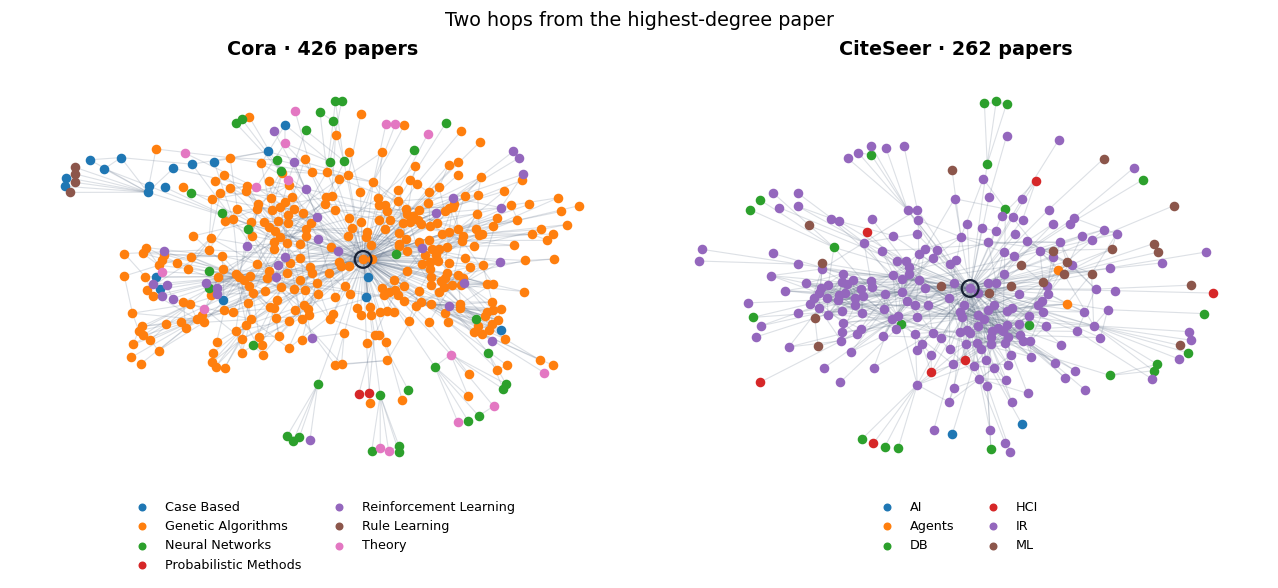

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
palette = plt.get_cmap("tab10").colors

for ax, (name, data) in zip(axes, datasets.items()):
    graph, labels = data["graph"], data["labels"]
    hub = max(graph.degree(), key=lambda item: item[1])[0]
    neighborhood = nx.ego_graph(graph, hub, radius=2)
    positions = nx.spring_layout(neighborhood, seed=SEED)
    topic_colors = dict(zip(sorted(labels.unique()), palette))
    nx.draw_networkx_edges(neighborhood, positions, ax=ax, alpha=0.22,
                           edge_color="#64748b", width=0.7)
    for topic, color in topic_colors.items():
        nodes = [node for node in neighborhood if labels.at[node] == topic]
        if nodes:
            nx.draw_networkx_nodes(
                neighborhood, positions, nodelist=nodes, node_color=[color],
                node_size=25, label=topic.replace("_", " "), ax=ax,
            )
    ax.scatter(*positions[hub], s=110, facecolors="none", edgecolors="#172133",
               linewidths=1.4, zorder=4)
    ax.set_title(f"{name} · {len(neighborhood):,} papers")
    ax.set_axis_off()
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0), ncols=2,
              frameon=False, fontsize=8, markerscale=0.8)

fig.suptitle("Two hops from the highest-degree paper")
plt.show()

## 5. Findings for the benchmarks

In [6]:
findings = []
for name, data in datasets.items():
    labels = data["labels"]
    counts = labels.value_counts()
    stats = graph_summary[name]
    findings.append(
        f"- **{name}** has a majority class of **{counts.index[0].replace('_', ' ')}** "
        f"({counts.iloc[0] / len(labels):.1%} of papers). Its largest component covers "
        f"**{stats['Largest component (%)']:.1f}%** of papers and "
        f"**{stats['Isolated papers']:,}** papers have no usable neighbors."
    )
    findings.append(
        f"  **{stats['Same-topic edges (%)']:.1f}%** of its edges connect papers with "
        f"the same topic, compared with **{stats['Expected same-topic edges after label shuffle (%)']:.1f}%** "
        f"expected after shuffling labels. The median paper has "
        f"**{np.median(data['active_words']):.0f}** active word features."
    )

display(Markdown("\n".join(findings)))

- **Cora** has a majority class of **Neural Networks** (30.2% of papers). Its largest component covers **91.8%** of papers and **0** papers have no usable neighbors.
  **81.0%** of its edges connect papers with the same topic, compared with **17.9%** expected after shuffling labels. The median paper has **20** active word features.
- **CiteSeer** has a majority class of **DB** (21.2% of papers). Its largest component covers **63.7%** of papers and **48** papers have no usable neighbors.
  **73.8%** of its edges connect papers with the same topic, compared with **17.9%** expected after shuffling labels. The median paper has **32** active word features.

Use the same stratified splits for both benchmarks. Same-topic citations give both models a reason to use graph structure. Isolates require explicit handling in DeepWalk because they have no neighboring papers to visit. A GCN with self-loops can still use an isolated paper's own word features.